In [ ]:
# Définition de l'outil de menu consultable
auto_tools = [get_menu]
tool_node = ToolNode(auto_tools)

# Liste globale des outils de gestion de commande
order_tools = [add_to_order, confirm_order, get_order, clear_order, place_order]

# Enregistrement de tous les outils disponibles auprès du LLM
llm_with_tools = llm.bind_tools(auto_tools + order_tools)

graph_builder = StateGraph(OrderState)

# Ajout de l'ensemble des nœuds constitutifs du workflow complet
graph_builder.add_node("chatbot", chatbot_with_tools)
graph_builder.add_node("human", human_node)
graph_builder.add_node("tools", tool_node)
graph_builder.add_node("ordering", order_node)

# Connexions décisionnelles et arêtes conditionnelles
graph_builder.add_conditional_edges("chatbot", maybe_route_to_tools)

# Rebouclage conditionnel de l'interaction humaine
graph_builder.add_conditional_edges("human", maybe_exit_human_node)

# Cycles de retours automatiques vers le chatbot après exécution des outils ou de l'état
graph_builder.add_edge("tools", "chatbot")
graph_builder.add_edge("ordering", "chatbot")

graph_builder.add_edge(START, "chatbot")
graph_with_order_tools = graph_builder.compile()

# Rendu final du graphe d'ordonnancement complet avec gestion des exceptions réseau de l'API externe
try:
    display(Image(graph_with_order_tools.get_graph().draw_mermaid_png(max_retries=5, retry_delay=2.0)))
except Exception as e:
    print("Note : Impossible de générer le schéma visuel du graphe car l'API externe Mermaid est actuellement indisponible.")
    print("Le graphe de commande a cependant bien été compilé et est prêt à être utilisé !")

# Construire un agent avec LangGraph et l'API Gemini

Bienvenue dans ce nouveau notebook du cours sur l'IA générative.

Dans ce notebook, vous allez utiliser [LangGraph](https://www.langchain.com/langgraph) pour définir une application à base de graphe et à état, construite au-dessus de l'API Gemini.

Vous allez créer un système simulé de commande dans un café, appelé BaristaBot. Il proposera aux clients une interface de chat en boucle pour commander des boissons en langage naturel. Vous construirez aussi des nœuds qui représentent le menu du café en temps réel et le système de commande « en coulisses ».

BaristaBot est utilisé dans d'autres démos de l'API Gemini. Si vous cherchez une version plus minimaliste, consultez l'[exemple BaristaBot avec appel de fonctions](https://github.com/google-gemini/cookbook/blob/main/examples/Agents_Function_Calling_Barista_Bot.ipynb), qui met en place un système similaire avec uniquement le SDK Python de l'API Gemini et l'appel de fonctions.

## **IMPORTANT !**

L'application de ce notebook récupère les **saisies de l'utilisateur** dans une **zone de texte** (la fonction [`input` de Python](https://docs.python.org/3/library/functions.html#input)). Ces appels sont commentés pour que vous puissiez utiliser **Exécution > Tout exécuter** sans interruption. Repérez bien les étapes où vous devez décommenter les appels `.invoke(...)` pour interagir avec l'application.

Si vous voulez de nouveau tout exécuter d'un coup, pensez à **recommenter** ces lignes pour que le notebook puisse tourner sans intervention.

> **Version adaptée pour Google Colab** : ce notebook est en français, lit la clé API depuis les **secrets Colab** et utilise le modèle `gemini-3.1-flash-lite` (les modèles Gemini 2.0 d'origine ont été arrêtés) avec les versions récentes de LangGraph et de LangChain. En cas de quota atteint, LangChain relance automatiquement les appels (paramètre `max_retries`). Le menu et les instructions du bot restent en anglais, mais vous pouvez commander en français : le modèle s'adapte.

## Configuration

Commencez par installer et importer le SDK LangGraph et l'intégration LangChain pour l'API Gemini.

In [ ]:
# Installation silencieuse de LangGraph, de l'intégration LangChain pour Gemini et des utilitaires préconstruits
# Les versions indiquées sont verrouillées pour garantir la stabilité et éviter les régressions
!pip install -qU "langgraph==1.2.12" "langchain-google-genai==4.4.0" "langgraph-prebuilt==1.1.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.2/250.2 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.6/81.6 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 29.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 263.5/263.5 kB 18.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.59.1 which is incompatible.


### Configurer votre clé API

La variable d'environnement `GOOGLE_API_KEY` permet de configurer automatiquement l'API sous-jacente. Cela fonctionne à la fois pour le SDK Python officiel de Gemini et pour LangChain/LangGraph.

Pour exécuter la cellule suivante, votre clé API doit être enregistrée dans un [secret Colab](https://colab.research.google.com/notebooks/secrets.ipynb) nommé `GOOGLE_API_KEY` :

1. Dans la barre latérale gauche de Colab, cliquez sur l'icône **clé** 🔑 (« Secrets »).
2. Cliquez sur **Ajouter un secret**, saisissez `GOOGLE_API_KEY` comme nom et collez votre clé comme valeur.
3. Activez l'interrupteur **Accès au notebook**.

Si vous n'avez pas encore de clé API, vous pouvez en obtenir une sur [AI Studio](https://aistudio.google.com/app/apikey). Vous trouverez des [instructions détaillées dans la documentation](https://ai.google.dev/gemini-api/docs/api-key).

Hors de Colab (exécution locale, VM…), la cellule utilise la variable d'environnement `GOOGLE_API_KEY`.

In [ ]:
import os

GOOGLE_API_KEY = None

# 1) Tentative de récupération de la clé API depuis les secrets de Google Colab (icône clé 🔑 à gauche)
try:
    from google.colab import userdata
    GOOGLE_API_KEY = userdata.get("GOOGLE_API_KEY")
except ImportError:
    pass  # Si on n'est pas dans un environnement Colab, on passe sans lever d'erreur

# 2) Alternative : récupération depuis la variable d'environnement (exécution locale, Docker, etc.)
if not GOOGLE_API_KEY:
    GOOGLE_API_KEY = os.environ.get("GOOGLE_API_KEY")

# Si aucune clé n'est trouvée, on lève une exception claire pour guider l'utilisateur
if not GOOGLE_API_KEY:
    raise ValueError(
        "Clé API introuvable : ajoutez un secret Colab nommé GOOGLE_API_KEY "
        "et activez « Accès au notebook »."
    )

# Configuration de la variable d'environnement globale pour que LangChain la détecte automatiquement
os.environ["GOOGLE_API_KEY"] = GOOGLE_API_KEY
print("Clé API chargée ✅")

Clé API chargée ✅


Si vous obtenez une erreur du type `SecretNotFoundError` ou `NotebookAccessError`, vérifiez que le secret s'appelle exactement `GOOGLE_API_KEY` **et** que l'interrupteur **Accès au notebook** est activé dans le panneau Secrets (icône clé). Colab peut aussi afficher une fenêtre vous demandant d'autoriser l'accès : cliquez sur **Autoriser l'accès**.

## Concepts clés

Les applications LangGraph reposent sur une structure de **graphe**. En tant que développeur, vous définissez un graphe d'application qui modélise les transitions d'état de votre application. Votre application définit un schéma d'**état** (*state*), et une instance de ce schéma circule dans le graphe.

Chaque **nœud** du graphe représente une action ou une étape possible. Les nœuds modifient l'état grâce au code que vous définissez. Ces modifications peuvent venir de l'appel d'un LLM, d'une API, ou de n'importe quelle logique définie dans le nœud.

Chaque **arête** du graphe représente une transition entre états et définit le déroulement du programme. Les transitions peuvent être fixes : par exemple, dans un chatbot purement textuel dont la réponse est toujours affichée à l'utilisateur, on passe toujours de `chatbot -> user`. Elles peuvent aussi être conditionnelles, ce qui permet d'ajouter des branchements (comme un `if-else`) ou des boucles (comme `for` ou `while`).

LangGraph est très extensible et offre de nombreuses fonctionnalités qui ne font pas partie de ce tutoriel, comme la mémoire, la persistance et le streaming. Pour mieux comprendre ses concepts clés et sa philosophie, consultez la [documentation de LangGraph](https://docs.langchain.com/oss/python/langgraph/overview).

## Définir les instructions de base

L'état est un concept fondamental d'une application LangGraph. Un objet d'état est transmis à chaque nœud et à chaque transition. Ici, vous définissez un objet d'état, `OrderState`, qui contient l'historique de la conversation, une commande structurée et un indicateur qui signale si le client a fini de commander. Pour simplifier, la « structure » de la commande est une simple liste de chaînes, mais on pourrait utiliser n'importe quelle structure de données Python.

En Python, l'objet d'état de LangGraph est un [dictionnaire](https://docs.python.org/3/library/stdtypes.html#dict). Vous pouvez lui donner un schéma en le définissant comme un [`TypedDict`](https://docs.python.org/3/library/typing.html#typing.TypedDict).

Vous définissez aussi l'instruction système utilisée par le modèle Gemini. Elle fixe le ton et le style, ainsi que les règles de fonctionnement du chatbot.

In [ ]:
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph.message import add_messages


# Définition de la structure de l'état (State) globale de notre graphe.
# Cet objet est partagé et modifié par les différents nœuds.
class OrderState(TypedDict):
    """État représentant la conversation de commande du client."""

    # Historique de la conversation.
    # L'annotation `add_messages` indique à LangGraph qu'à chaque retour de nœud,
    # les nouveaux messages doivent être ajoutés à la suite et non remplacer l'historique.
    messages: Annotated[list, add_messages]

    # Liste de chaînes de caractères représentant les articles de la commande en cours.
    order: list[str]

    # Booléen indiquant si l'utilisateur a validé sa commande et terminé la session.
    finished: bool


# L'instruction système définit la personnalité du bot, les règles du menu,
# et la séquence d'outils qu'il doit impérativement appeler pour valider une commande.
BARISTABOT_SYSINT = (
    "system",
    "You are a BaristaBot, an interactive cafe ordering system. A human will talk to you about the "
    "available products you have and you will answer any questions about menu items (and only about "
    "menu items - no off-topic discussion, but you can chat about the products and their history). "
    "The customer will place an order for 1 or more items from the menu, which you will structure "
    "and send to the ordering system after confirming the order with the human. "
    "\n\n"
    "Add items to the customer's order with add_to_order, and reset the order with clear_order. "
    "To see the contents of the order so far, call get_order (this is shown to you, not the user) "
    "Always confirm_order with the user (double-check) before calling place_order. Calling confirm_order will "
    "display the order items to the user and returns their response to seeing the list. Their response may contain modifications. "
    "Always verify and respond with drink and modifier names from the MENU before adding them to the order. "
    "If you are unsure a drink or modifier matches those on the MENU, ask a question to clarify or redirect. "
    "You only have the modifiers listed on the menu. "
    "Once the customer has finished ordering items, Call confirm_order to ensure it is correct then make "
    "any necessary updates and then call place_order. Once place_order has returned, thank the user and "
    "say goodbye!"
    "\n\n"
    "If any of the tools are unavailable, you can break the fourth wall and tell the user that "
    "they have not implemented them yet and should keep reading to do so.",
)

# Message d'accueil par défaut que le robot affichera au tout début de la conversation.
WELCOME_MSG = "Bienvenue au café BaristaBot. Tapez `q` pour quitter. Que puis-je vous servir aujourd'hui ?"

## Définir un chatbot à un seul tour

Pour illustrer le fonctionnement de LangGraph, le programme suivant définit un nœud chatbot qui exécute un seul tour de conversation avec les instructions fournies.

Chaque nœud du graphe agit sur l'objet d'état. L'état (un dictionnaire Python) est passé en paramètre au nœud (une fonction), qui renvoie le nouvel état. En pseudo-code : `state = node(state)`.

Remarque : pour le nœud `chatbot`, l'état est mis à jour en *ajoutant* le nouveau message. L'annotation `add_messages` sur `OrderState.messages` indique que les messages renvoyés par un nœud sont *ajoutés* à la suite. Normalement, l'état est mis à jour par remplacement, mais cette annotation change le comportement de `messages`.

> **Gemini 3** : le contenu d'une réponse (`msg.content`) peut être une liste de blocs (texte, signature de réflexion…). Pour afficher uniquement le texte, on utilise `msg.text`.

In [ ]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI

# Spécification du modèle de fondation. Gemini 3.1 Flash-lite offre un excellent compromis vitesse/coût
MODEL = "gemini-3.1-flash-lite"

# Initialisation du LLM via l'intégration LangChain pour Google GenAI
# max_retries=6 permet de réessayer automatiquement si l'API renvoie des erreurs de quota temporaires (HTTP 429)
llm = ChatGoogleGenerativeAI(model=MODEL, max_retries=6)


def chatbot(state: OrderState) -> OrderState:
    """Nœud du chatbot : récupère l'historique, applique l'instruction système et appelle le LLM."""
    # On concatène l'instruction système avec l'historique complet des messages stockés dans l'état
    message_history = [BARISTABOT_SYSINT] + state["messages"]

    # On retourne un dictionnaire avec la clé 'messages' contenant la réponse du LLM.
    # Grâce à add_messages, cette réponse sera ajoutée au lieu d'écraser l'historique.
    return {"messages": [llm.invoke(message_history)]}


# Initialisation de notre constructeur de graphe en lui passant notre schéma d'état
graph_builder = StateGraph(OrderState)

# Ajout du nœud 'chatbot' associé à la fonction définie ci-dessus
graph_builder.add_node("chatbot", chatbot)

# Définition de la transition initiale : le point d'entrée START pointe directement vers le chatbot
graph_builder.add_edge(START, "chatbot")

# Compilation du graphe pour le rendre exécutable
chat_graph = graph_builder.compile()

Il peut être utile de visualiser le graphe que vous venez de définir. Le code suivant en affiche le rendu.

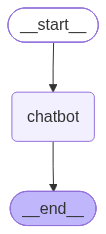

In [ ]:
from IPython.display import Image, display

# Génération et affichage d'un diagramme au format PNG généré par Mermaid représentant la structure du graphe actuel
display(Image(chat_graph.get_graph().draw_mermaid_png()))

Maintenant que le graphe est défini, vous pouvez l'exécuter. Il n'a qu'un nœud et une transition vers ce nœud : il passe donc de `__start__` à `chatbot`, exécute le nœud `chatbot`, puis s'arrête.

Pour exécuter le graphe, appelez `invoke` avec un objet d'état initial. Ici, il commence par le premier message de l'utilisateur.

In [ ]:
from pprint import pprint

# Message initial de l'utilisateur
user_msg = "Bonjour, que savez-vous faire ?"

# Appel du graphe avec l'état de départ contenant le premier message
state = chat_graph.invoke({"messages": [user_msg]})

# Affichage propre de la conversation séquentielle stockée dans l'état final
for msg in state["messages"]:
    print(f"{type(msg).__name__}: {msg.text}")

HumanMessage: Bonjour, que savez-vous faire ?
AIMessage: Bonjour ! Je suis BaristaBot, votre assistant café personnel. Je suis ici pour vous guider à travers notre sélection de boissons et pour prendre votre commande.

Voici ce que je peux faire pour vous :
*   **Répondre à vos questions** sur notre menu (ingrédients, histoire des boissons, etc.).
*   **Enregistrer votre commande** avec les options et modificateurs de votre choix.
*   **Finaliser votre commande** pour que vous puissiez déguster votre boisson rapidement.

Pour commencer, voici les produits disponibles :
*   **Espresso** (Simple ou Double)
*   **Americano**
*   **Cappuccino** (Lait entier, Lait d'avoine, ou Lait de soja)
*   **Latte** (Lait entier, Lait d'avoine, ou Lait de soja)
*   **Thé Earl Grey**

Que puis-je vous préparer aujourd'hui ?


Vous pourriez exécuter ceci dans une boucle Python, mais pour simplifier, lancez manuellement un tour de conversation supplémentaire. Ce second appel reprend l'état du premier et y ajoute un nouveau message de l'utilisateur pour obtenir une autre réponse du chatbot.

In [ ]:
# Définition d'un second tour manuel de conversation pour simuler la suite
user_msg = "Super, quels types de latte pouvez-vous préparer ?"

# Ajout du message de l'utilisateur à l'historique existant
state["messages"].append(user_msg)

# Ré-exécution du graphe avec l'état mis à jour pour obtenir la réponse du LLM
state = chat_graph.invoke(state)

# Affichage de toute la conversation accumulée
for msg in state["messages"]:
    print(f"{type(msg).__name__}: {msg.text}")

HumanMessage: Bonjour, que savez-vous faire ?
AIMessage: Bonjour ! Je suis BaristaBot, votre assistant café personnel. Je suis ici pour vous guider à travers notre sélection de boissons et pour prendre votre commande.

Voici ce que je peux faire pour vous :
*   **Répondre à vos questions** sur notre menu (ingrédients, histoire des boissons, etc.).
*   **Enregistrer votre commande** avec les options et modificateurs de votre choix.
*   **Finaliser votre commande** pour que vous puissiez déguster votre boisson rapidement.

Pour commencer, voici les produits disponibles :
*   **Espresso** (Simple ou Double)
*   **Americano**
*   **Cappuccino** (Lait entier, Lait d'avoine, ou Lait de soja)
*   **Latte** (Lait entier, Lait d'avoine, ou Lait de soja)
*   **Thé Earl Grey**

Que puis-je vous préparer aujourd'hui ?
HumanMessage: Super, quels types de latte pouvez-vous préparer ?
AIMessage: C'est une excellente question ! Le Latte est un classique indémodable : il se compose d'un espresso riche 

## Ajouter un nœud humain

Au lieu d'exécuter le graphe plusieurs fois dans une boucle Python, vous pouvez utiliser LangGraph pour boucler entre les nœuds.

Le nœud `human` affiche à l'utilisateur le dernier message du LLM, puis lui demande sa saisie suivante. Ici, on utilise les fonctions Python standard `print` et `input`, mais dans un vrai café, on pourrait afficher le chat sur un écran ou le lire à voix haute, et recevoir la saisie par un micro ou un clavier tactile.

La fonction du nœud `chatbot` a aussi été mise à jour pour inclure le message d'accueil qui démarre la conversation.

In [ ]:
from langchain_core.messages.ai import AIMessage


def human_node(state: OrderState) -> OrderState:
    """Nœud d'interaction humaine : affiche la réponse de l'IA et capture la saisie de l'utilisateur."""
    # Récupération du tout dernier message (qui provient de l'AIMessage du chatbot)
    last_msg = state["messages"][-1]
    print("Modèle :", last_msg.text)

    # Attente d'une saisie utilisateur interactive dans le terminal
    user_input = input("Vous : ")

    # Détection des mots-clés de sortie pour mettre à jour le flag 'finished'
    if user_input in {"q", "quit", "exit", "goodbye", "quitter", "au revoir"}:
        state["finished"] = True

    # Retour de l'état fusionné avec le nouveau HumanMessage saisi
    return state | {"messages": [("user", user_input)]}


def chatbot_with_welcome_msg(state: OrderState) -> OrderState:
    """Nœud du chatbot prenant en charge le message d'accueil si la conversation débute."""
    if state["messages"]:
        # S'il y a déjà des messages, on poursuit l'échange normal avec Gemini
        new_output = llm.invoke([BARISTABOT_SYSINT] + state["messages"])
    else:
        # Si la liste de messages est vide, on génère le message d'accueil statique
        new_output = AIMessage(content=WELCOME_MSG)

    return state | {"messages": [new_output]}


# Initialisation d'un nouveau graphe pour connecter notre chatbot et l'humain
graph_builder = StateGraph(OrderState)

# Enregistrement des nœuds de dialogue
graph_builder.add_node("chatbot", chatbot_with_welcome_msg)
graph_builder.add_node("human", human_node)

# Configuration des liens de base
graph_builder.add_edge(START, "chatbot")
graph_builder.add_edge("chatbot", "human")

Avant d'exécuter ce graphe, remarquez que si vous ajoutiez une arête de `human` vers `chatbot`, le graphe tournerait indéfiniment, faute de condition de sortie. Une façon de casser la boucle est de vérifier si l'utilisateur a saisi `q` ou `quit`, et de sortir dans ce cas.

Dans LangGraph, on utilise pour cela une arête conditionnelle. C'est une transition comme les autres, sauf qu'une fonction personnalisée est appelée pour choisir l'arête à emprunter.

Les fonctions d'arête conditionnelle prennent l'état en entrée et renvoient une chaîne : le nom du nœud vers lequel aller.

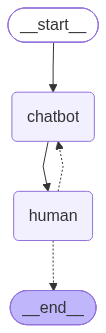

In [ ]:
from typing import Literal


def maybe_exit_human_node(state: OrderState) -> Literal["chatbot", "__end__"]:
    """Fonction d'arête conditionnelle décidant de reboucler ou de terminer le graphe."""
    if state.get("finished", False):
        # Si le flag finished est True, on dirige vers le nœud spécial END pour s'arrêter
        return END
    else:
        # Sinon, on retourne au chatbot pour continuer à discuter
        return "chatbot"


# Ajout de la transition conditionnelle en sortie du nœud human
ggraph_builder = graph_builder.add_conditional_edges("human", maybe_exit_human_node)

# Compilation du graphe interactif
chat_with_human_graph = graph_builder.compile()

# Rendu visuel de la structure du graphe avec la boucle conditionnelle
Image(chat_with_human_graph.get_graph().draw_mermaid_png())

Exécutez ce nouveau graphe pour voir comment la boucle d'interaction est maintenant gérée par le graphe. Tapez `q` pour quitter.

**Vous devez décommenter la ligne `.invoke(...)` pour exécuter cette étape.**

In [ ]:
# Paramétrage de la limite maximale d'étapes (évite les boucles infinies accidentelles)
config = {"recursion_limit": 100}

# Décommentez et exécutez la ligne suivante pour lancer la discussion interactive :
# state = chat_with_human_graph.invoke({"messages": []}, config)

# pprint(state)

Modèle : Bienvenue au café BaristaBot. Tapez `q` pour quitter. Que puis-je vous servir aujourd'hui ?
Vous : bonjour
Modèle : Bonjour ! Bienvenue chez BaristaBot. Je serais ravi de vous préparer une boisson. 

Voici notre menu pour aujourd'hui :

*   **Espresso** (Simple ou Double)
*   **Americano**
*   **Cappuccino**
*   **Latte** (Classique, Vanille, Caramel)
*   **Chocolat Chaud**
*   **Thé Earl Grey**

**Modificateurs disponibles :**
*   Lait : Entier, Avoine (+0.50€), Amande (+0.50€)
*   Sucre : Sans sucre, 1 sucre, 2 sucres

Que puis-je vous préparer ?
Vous : the
Modèle : C'est noté pour le thé Earl Grey ! Souhaitez-vous ajouter du lait ou du sucre à votre thé ? Si oui, lequel ou combien de sucres ?
Vous : non sans sucre ou autre
Modèle : Parfait, un thé Earl Grey nature. Je l'ajoute à votre commande.

Souhaitez-vous commander autre chose ou est-ce tout pour aujourd'hui ?
Vous : no merci
Modèle : 
Vous : q
{'finished': True,
 'messages': [AIMessage(content="Bienvenue au café Baris

## Ajouter un menu « en direct »

Pour l'instant, BaristaBot ne connaît pas les produits disponibles au café : il va donc inventer un menu (halluciner). Une option serait d'inscrire le menu en dur dans le prompt système. Cela fonctionnerait bien, mais pour simuler un menu plus dynamique, qui pourrait suivre l'état des stocks, vous allez placer le menu dans un outil personnalisé.

Ce système utilise deux types d'outils : des outils sans état, qui peuvent être exécutés automatiquement, et des outils avec état, qui modifient la commande. L'outil « menu actuel » est sans état : il ne modifie pas la commande en cours, il peut donc être appelé automatiquement.

Dans une application LangGraph, vous pouvez transformer des fonctions Python en outils avec le décorateur `@tool`.

In [ ]:
from langchain_core.tools import tool


@tool
def get_menu() -> str:
    """Provide the latest up-to-date menu."""
    # Cet outil est statique ici, mais pourrait facilement interroger une base de données externe.
    # Il renvoie le menu complet avec les boissons, les options, et gère les ruptures de stock.
    return """
    MENU:
    Coffee Drinks:
    Espresso
    Americano
    Cold Brew

    Coffee Drinks with Milk:
    Latte
    Cappuccino
    Cortado
    Macchiato
    Mocha
    Flat White

    Tea Drinks:
    English Breakfast Tea
    Green Tea
    Earl Grey

    Tea Drinks with Milk:
    Chai Latte
    Matcha Latte
    London Fog

    Other Drinks:
    Steamer
    Hot Chocolate

    Modifiers:
    Milk options: Whole, 2%, Oat, Almond, 2% Lactose Free; Default option: whole
    Espresso shots: Single, Double, Triple, Quadruple; default: Double
    Caffeine: Decaf, Regular; default: Regular
    Hot-Iced: Hot, Iced; Default: Hot
    Sweeteners (option to add one or more): vanilla sweetener, hazelnut sweetener, caramel sauce, chocolate sauce, sugar free vanilla sweetener
    Special requests: any reasonable modification that does not involve items not on the menu, for example: 'extra hot', 'one pump', 'half caff', 'extra foam', etc.

    "dirty" means add a shot of espresso to a drink that doesn't usually have it, like "Dirty Chai Latte".
    "Regular milk

Ajoutez maintenant ce nouvel outil au graphe. L'outil `get_menu` est placé dans un [`ToolNode`](https://docs.langchain.com/oss/python/langgraph/workflows-agents), qui se charge d'appeler l'outil et de transmettre sa réponse sous forme de message dans le graphe. Les outils sont aussi liés à l'objet `llm`, pour que le modèle sache qu'ils existent. Comme vous avez maintenant un autre objet `llm` à appeler, il faut mettre à jour le nœud `chatbot` pour qu'il connaisse les outils.

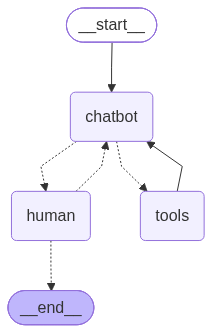

In [ ]:
from langgraph.prebuilt import ToolNode


# Regroupement des outils système automatiques
tools = [get_menu]
tool_node = ToolNode(tools)

# Association fonctionnelle des outils au modèle LLM
llm_with_tools = llm.bind_tools(tools)


def maybe_route_to_tools(state: OrderState) -> Literal["tools", "human"]:
    """Décide si l'étape suivante nécessite d'appeler l'outil de menu ou de passer à l'humain."""
    if not (msgs := state.get("messages", [])):
        raise ValueError(f"No messages found when parsing state: {state}")

    msg = msgs[-1]

    # Si le LLM a généré une intention d'appel d'outil (tool_calls), on l'envoie vers le nœud d'exécution
    if hasattr(msg, "tool_calls") and len(msg.tool_calls) > 0:
        return "tools"
    else:
        return "human"


def chatbot_with_tools(state: OrderState) -> OrderState:
    """Version enrichie du nœud de chatbot prenant en charge la liaison des outils."""
    defaults = {"order": [], "finished": False}

    if state["messages"]:
        # Appel de l'instance LLM configurée avec l'accès aux outils bindés
        new_output = llm_with_tools.invoke([BARISTABOT_SYSINT] + state["messages"])
    else:
        new_output = AIMessage(content=WELCOME_MSG)

    return defaults | state | {"messages": [new_output]}


# Reconstruction du graphe intégrant le cycle d'exécution d'outils (ToolNode)
graph_builder = StateGraph(OrderState)

graph_builder.add_node("chatbot", chatbot_with_tools)
graph_builder.add_node("human", human_node)
graph_builder.add_node("tools", tool_node)

# Arêtes conditionnelles et de retour d'état
graph_builder.add_conditional_edges("chatbot", maybe_route_to_tools)
graph_builder.add_conditional_edges("human", maybe_exit_human_node)
graph_builder.add_edge("tools", "chatbot")  # Après l'exécution d'un outil, on repasse toujours par le chatbot pour formuler la réponse

graph_builder.add_edge(START, "chatbot")
graph_with_menu = graph_builder.compile()

# Visualisation de la structure avec le nœud 'tools' intégré
Image(graph_with_menu.get_graph().draw_mermaid_png())

Exécutez maintenant le nouveau graphe pour voir comment le modèle utilise le menu.

**Vous devez décommenter la ligne `.invoke(...)` pour exécuter cette étape.**

In [ ]:
# Décommentez et exécutez cette ligne pour tester le graphe avec menu interactif :
# state = graph_with_menu.invoke({"messages": []}, config)

# pprint(state)

Modèle : Bienvenue au café BaristaBot. Tapez `q` pour quitter. Que puis-je vous servir aujourd'hui ?
Vous : hii
Modèle : Bonjour ! Bienvenue au café. Que puis-je vous servir aujourd'hui ? Si vous souhaitez voir ce que nous proposons, n'hésitez pas à me demander le menu !
Vous : thanks
Modèle : Je vous en prie ! Souhaitez-vous consulter notre menu pour voir ce que nous proposons aujourd'hui ?
Vous : no
Modèle : Très bien ! N'hésitez pas si vous changez d'avis ou si vous savez déjà ce qui vous ferait plaisir. Je suis là pour prendre votre commande quand vous serez prêt.
Vous : q
{'finished': True,
 'messages': [AIMessage(content="Bienvenue au café BaristaBot. Tapez `q` pour quitter. Que puis-je vous servir aujourd'hui ?", additional_kwargs={}, response_metadata={}, id='71564884-994d-46cf-9bea-99edaad2a433', tool_calls=[], invalid_tool_calls=[]),
              HumanMessage(content='hii', additional_kwargs={}, response_metadata={}, id='ddf8df7a-14f8-4f83-8629-911dac053e6a'),
              

## Gérer les commandes

Pour construire une commande au fil de la conversation, vous devez mettre à jour l'état pour suivre la commande, et fournir des outils simples qui modifient cet état. Ces outils doivent être explicites : le modèle ne doit pas accéder directement à l'état interne de l'application, sinon il risquerait d'être manipulé de façon arbitraire.

Les outils de commande seront traités dans un nœud séparé, pour pouvoir modifier l'état directement. Le décorateur `@tool` reste pratique pour définir leur schéma : les outils de commande ci-dessous sont donc des fonctions Python vides.

In [ ]:
from collections.abc import Iterable
from random import randint

from langchain_core.messages.tool import ToolMessage

# Déclaration de signatures d'outils vides via @tool.
# Leurs exécutions concrètes et modifications d'état seront gérées de manière sécurisée et centralisée par 'order_node'.

@tool
def add_to_order(drink: str, modifiers: Iterable[str]) -> str:
    """Adds the specified drink to the customer's order, including any modifiers.

    Returns:
      The updated order in progress.
    """


@tool
def confirm_order() -> str:
    """Asks the customer if the order is correct.

    Returns:
      The user's free-text response.
    """


@tool
def get_order() -> str:
    """Returns the users order so far. One item per line."""


@tool
def clear_order():
    """Removes all items from the user's order."""


@tool
def place_order() -> int:
    """Sends the order to the barista for fulfillment.

    Returns:
      The estimated number of minutes until the order is ready.
    """


def order_node(state: OrderState) -> OrderState:
    """Nœud métier de commande : applique les changements réels sur l'état de la commande (Order State)."""
    tool_msg = state.get("messages", [])[-1]
    order = state.get("order", [])
    outbound_msgs = []
    order_placed = False

    # Itération sur l'ensemble des appels d'outils demandés par le LLM
    for tool_call in tool_msg.tool_calls:

        if tool_call["name"] == "add_to_order":
            modifiers = tool_call["args"]["modifiers"]
            modifier_str = ", ".join(modifiers) if modifiers else "no modifiers"
            order.append(f'{tool_call["args"]["drink"]} ({modifier_str})')
            response = "\n".join(order)

        elif tool_call["name"] == "confirm_order":
            # Rendu explicite de la commande dans le flux standard pour confirmation finale
            print("Votre commande :")
            if not order:
                print("  (aucun article)")
            for drink in order:
                print(f"  {drink}")
            response = input("Est-ce correct ? ")

        elif tool_call["name"] == "get_order":
            response = "\n".join(order) if order else "(no order)"

        elif tool_call["name"] == "clear_order":
            order.clear()
            response = None

        elif tool_call["name"] == "place_order":
            order_text = "\n".join(order)
            print("Envoi de la commande en cuisine !")
            print(order_text)
            order_placed = True
            response = randint(1, 5)  # Génération aléatoire du temps d'attente estimé

        else:
            raise NotImplementedError(f'Appel d\'outil inconnu : {tool_call["name"]}')

        # Création et empilement des messages de retour d'outils indispensables pour informer le LLM de l'exécution
        outbound_msgs.append(
            ToolMessage(
                content=str(response),
                name=tool_call["name"],
                tool_call_id=tool_call["id"],
            )
        )

    return {"messages": outbound_msgs, "order": order, "finished": order_placed}


def maybe_route_to_tools(state: OrderState) -> str:
    """Système de routage intelligent distinguant les outils système (menu) et les outils métier (commande)."""
    if not (msgs := state.get("messages", [])):
        raise ValueError(f"No messages found when parsing state: {state}")

    msg = msgs[-1]

    if state.get("finished", False):
        return END

    elif hasattr(msg, "tool_calls") and len(msg.tool_calls) > 0:
        # Si c'est un appel de get_menu, on l'envoie sur le nœud 'tools' standard
        if any(
            tool["name"] in tool_node.tools_by_name.keys() for tool in msg.tool_calls
        ):
            return "tools"
        # Sinon, l'outil est délégué au nœud métier 'ordering'
        else:
            return "ordering"

    else:
        return "human"

Définissez maintenant le graphe. Le LLM doit aussi connaître les outils pour pouvoir les appeler. Vous créez ici 2 ensembles d'outils, correspondant aux nœuds qui les traitent : automatiques et de commande.

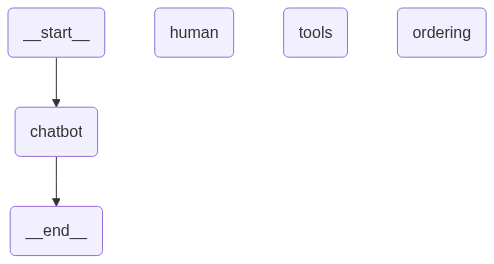

In [ ]:
# Les outils automatiques sont appelés automatiquement par le ToolNode
auto_tools = [get_menu]
tool_node = ToolNode(auto_tools)

# Les outils de commande sont traités par le nœud de commande.
order_tools = [add_to_order, confirm_order, get_order, clear_order, place_order]

# Le LLM doit connaître tous les outils : on les indique tous ici.
llm_with_tools = llm.bind_tools(auto_tools + order_tools)


graph_builder = StateGraph(OrderState)

# Nœuds
graph_builder.add_node("chatbot", chatbot_with_tools)
graph_builder.add_node("human", human_node)
graph_builder.add_node("tools", tool_node)
graph_builder.add_node("ordering", order_node)

# Chatbot -> {ordering, tools, human, END}
graph_builder.add_conditional_edges("chatbot", maybe_route_to_tools)
# Human -> {chatbot, END}
graph_builder.add_conditional_edges("human", maybe_exit_human_node)

# Après les outils (des deux types), on revient toujours au chatbot.
graph_builder.add_edge("tools", "chatbot")
graph_builder.add_edge("ordering", "chatbot")

graph_builder.add_edge(START, "chatbot")
graph_with_order_tools = graph_builder.compile()

# Essaye d'afficher le graphe, mais ne bloque pas si l'API Mermaid externe est indisponible (Erreur 503)
try:
    display(Image(graph_with_order_tools.get_graph().draw_mermaid_png(max_retries=5, retry_delay=2.0)))
except Exception as e:
    print("Note : Impossible de générer le schéma visuel du graphe car l'API externe Mermaid est actuellement indisponible.")
    print("Le graphe de commande a cependant bien été compilé et est prêt à être utilisé !")

Exécutez maintenant le graphe complet du système de commande.

**Vous devez décommenter la ligne `.invoke(...)` pour exécuter cette étape.**

In [ ]:
# Décommentez et exécutez cette ligne pour démarrer l'application finale BaristaBot complète :
# state = graph_with_order_tools.invoke({"messages": []}, config)

# pprint(state)

Modèle : Bienvenue au café BaristaBot. Tapez `q` pour quitter. Que puis-je vous servir aujourd'hui ?
Vous : hi
Modèle : Bonjour ! Bienvenue au café BaristaBot. Que puis-je vous préparer aujourd'hui ? Si vous souhaitez voir ce que nous proposons, n'hésitez pas à me demander le menu.
Vous : menu
Modèle : Voici notre menu complet :

**Coffee Drinks :**
* Espresso
* Americano
* Cold Brew

**Coffee Drinks with Milk :**
* Latte
* Cappuccino
* Cortado
* Macchiato
* Mocha
* Flat White

**Tea Drinks :**
* English Breakfast Tea
* Green Tea
* Earl Grey

**Tea Drinks with Milk :**
* Chai Latte
* Matcha Latte
* London Fog

**Other Drinks :**
* Steamer
* Hot Chocolate

**Modifiers :**
* **Milk :** Whole, 2%, Oat, Almond, 2% Lactose Free (Default: Whole). *Note : Nous sommes en rupture de stock de lait de soja.*
* **Espresso shots :** Single, Double, Triple, Quadruple (Default: Double).
* **Caffeine :** Decaf, Regular (Default: Regular).
* **Hot-Iced :** Hot, Iced (Default: Hot).
* **Sweeteners :** V

L'état de la commande a été enregistré à la fois dans la fonction `place_order` et dans l'état final de la conversation renvoyé par l'exécution du graphe. Cela montre comment intégrer vos propres systèmes dans une application à base de graphe, et comment récupérer les résultats finaux de son exécution.

In [ ]:
# Décommentez pour imprimer de façon brute les articles présents dans la liste finale de la commande
# pprint(state["order"])

[]
